# Symbolic Detective v0.2 — Geometry Ablation Analysis

**Comparison:** `v0.2_dev_baseline` vs. `exp*`:
1. **Retrieval CV:** Hit@1, Hit@5 and MRR, overall and for `eight_pointed_star`, at every α.
2. **Paired fold changes:** Whether an improvement is consistent across the same five folds.
3. **Top-1 multi-class discrimination:** Per-class precision/recall/F1, plus micro/macro/weighted averages.

**Reading the results:** CV means/SDs are computed across folds; discrimination reports are based on **pooled predictions** across folds. Those summaries are not interchangeable. Positive Δ means harmonics > baseline.

*Class voting is a separate evaluation; these files contain retrieval and Top-1 discrimination only.*

## 1. Load baseline and harmonics JSON

In [42]:
import json
from pathlib import Path
from IPython.display import display
try:
    import seaborn as sns
    import matplotlib.pyplot as plt
    import pandas as pd
    import numpy as np
except ImportError:
    # If any are missing, install them quietly
    print("Libraries missing. Installing now...")
    %pip install -q matplotlib seaborn pandas
    print("Installation complete!")
    
    import seaborn as sns
    import matplotlib.pyplot as plt
    import pandas as pd
    import numpy as np

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)

# Locate project results directory
cwd = Path.cwd()
search_roots = [cwd, *cwd.parents]

results_root = next((
        root / "results"
        for root in search_roots
        if (root / "results/v0.2_dev_baseline/retrieval_metrics.json").is_file()),None,)

if results_root is None:
    raise FileNotFoundError("Could not locate v0.2 development baseline.")

selected_experiment = "peaks"  # harmonics, peaks, pointedness, radius, central_structure

# Discover available experiments
available_paths = {
    path.parent.name.split("_", 1)[1]: path
    for path in sorted(
        (results_root / "v0.2_dev").glob("exp*/retrieval_metrics.json")
    )
}

if selected_experiment not in available_paths:
    raise ValueError(f"Experiment '{selected_experiment}' not found. Available: {list(available_paths)}")

# Load only baseline and selected experiment
experiment_paths = {
    "baseline": results_root / "v0.2_dev_baseline/retrieval_metrics.json",
    selected_experiment: available_paths[selected_experiment],
}

experiments = {}
for name, path in experiment_paths.items():
    with path.open(encoding="utf-8") as f:
        experiments[name] = json.load(f)
    print(f"{name}: {path.parent.name}")

baseline = experiments["baseline"]
print(f"\nLoaded {len(experiments)} experiments.")

baseline: v0.2_dev_baseline
peaks: exp02_peaks

Loaded 2 experiments.


## 2. Cross-validation retrieval comparison

Compare the two representations for **every α** and for both evaluation scopes. The reported Δ is the difference between **unrounded** fold means.

In [43]:
def flatten_retrieval(data, experiment):
    rows = []

    for scope, configurations in data["cross_validation"].items():
        for cfg in configurations:
            for metric in ("hit_at_1", "hit_at_5", "mrr"):
                values = cfg[metric]

                rows.append({
                    "experiment": experiment,
                    "scope": scope,
                    "alpha": float(cfg["alpha"]),
                    "metric": metric,
                    "mean": values["mean"],
                    "std": values["std"],
                    "folds": values["folds"],
                })

    return pd.DataFrame(rows)

retrieval = pd.concat(
    [flatten_retrieval(data, name) for name, data in experiments.items()],
    ignore_index=True,
)
keys = ["scope", "alpha", "metric"]

# Baseline reference
comparison = (
    retrieval[retrieval["experiment"] == "baseline"]
    [keys + ["mean", "std"]]
    .rename(columns={
        "mean": "baseline_mean",
        "std": "baseline_std",
    })
)

columns = keys + ["baseline_mean", "baseline_std"]

# Compare every discovered experiment against baseline
for name in experiments:
    if name == "baseline":
        continue

    current = (
        retrieval[retrieval["experiment"] == name]
        [keys + ["mean", "std"]]
        .rename(columns={
            "mean": f"{name}_mean",
            "std": f"{name}_std",
        })
    )
    comparison = comparison.merge(current, on=keys, how="left", validate="one_to_one")
    delta_col = f"delta_{name}"
    comparison[delta_col] = (comparison[f"{name}_mean"] - comparison["baseline_mean"])
    columns.extend([f"{name}_mean", f"{name}_std", delta_col])

# Identify all delta columns
delta_cols = [c for c in columns if c.startswith("delta_")]

# Display all retrieval scopes with delta columns in blue
for scope in comparison["scope"].unique():
    print(f"\n{scope.upper()}")
    subset = comparison.loc[comparison["scope"] == scope, columns].round(4)
    styled = subset.style.map(
        lambda _: "color: #1f77b4; font-weight: 500;", subset=delta_cols
    )
    display(styled)


OVERALL


,scope,alpha,metric,baseline_mean,baseline_std,peaks_mean,peaks_std,delta_peaks
0,overall,0.000000,hit_at_1,0.604200,0.063600,0.604200,0.063600,0.000000
1,overall,0.000000,hit_at_5,0.876900,0.019300,0.876900,0.019300,0.000000
2,overall,0.000000,mrr,0.720000,0.039700,0.720000,0.039700,0.000000
3,overall,0.250000,hit_at_1,0.605800,0.037400,0.596200,0.055000,-0.009500
4,overall,0.250000,hit_at_5,0.871600,0.042800,0.879900,0.050000,0.008300
5,overall,0.250000,mrr,0.719300,0.035900,0.714600,0.041500,-0.004700
6,overall,0.500000,hit_at_1,0.497900,0.074900,0.514600,0.076200,0.016700
7,overall,0.500000,hit_at_5,0.890700,0.039100,0.894600,0.045300,0.003900
8,overall,0.500000,mrr,0.665400,0.055200,0.675400,0.054800,0.010100
9,overall,0.750000,hit_at_1,0.354300,0.110200,0.366700,0.063800,0.012500



TARGET_EIGHT_POINTED_STAR


,scope,alpha,metric,baseline_mean,baseline_std,peaks_mean,peaks_std,delta_peaks
15,target_eight_pointed_star,0.000000,hit_at_1,0.752500,0.058900,0.752500,0.058900,0.000000
16,target_eight_pointed_star,0.000000,hit_at_5,0.960000,0.049000,0.960000,0.049000,0.000000
17,target_eight_pointed_star,0.000000,mrr,0.829300,0.044000,0.829300,0.044000,0.000000
18,target_eight_pointed_star,0.250000,hit_at_1,0.745900,0.086300,0.745900,0.086300,0.000000
19,target_eight_pointed_star,0.250000,hit_at_5,0.937800,0.051000,0.937800,0.051000,0.000000
20,target_eight_pointed_star,0.250000,mrr,0.834200,0.075000,0.831000,0.072800,-0.003200
21,target_eight_pointed_star,0.500000,hit_at_1,0.666600,0.075500,0.686600,0.068100,0.020000
22,target_eight_pointed_star,0.500000,hit_at_5,0.960000,0.080000,0.935600,0.087900,-0.024400
23,target_eight_pointed_star,0.500000,mrr,0.786600,0.055700,0.799900,0.068400,0.013200
24,target_eight_pointed_star,0.750000,hit_at_1,0.458300,0.118300,0.414200,0.134200,-0.044000


### 2.1 Fold-by-fold paired differences

Because the JSON includes arrays of values for each fold, we can examine the **difference on each fold**, not just the difference between overall means. This assumes matching fold order / split; verify that the two evaluations used the same fold assignments.

In [44]:
keys = ["scope", "alpha", "metric"]

# Baseline fold results
baseline_folds = (
    retrieval[retrieval["experiment"] == "baseline"]
    [keys + ["folds"]]
    .rename(columns={"folds": "baseline_folds"})
)

# All feature experiments
experiment_folds = (
    retrieval[retrieval["experiment"] != "baseline"]
    [["experiment"] + keys + ["folds"]]
    .rename(columns={"folds": "experiment_folds"})
)

paired = experiment_folds.merge(baseline_folds, on=keys, validate="many_to_one")

# Compare individual folds
fold_rows = []
for row in paired.itertuples(index=False):
    original = np.asarray(row.baseline_folds, dtype=float)
    improved = np.asarray(row.experiment_folds, dtype=float)

    if len(original) != len(improved):
        raise ValueError(f"Different fold counts: {row.experiment}, {row.scope}, α={row.alpha}, {row.metric}")

    for fold_i, (old, new) in enumerate(zip(original, improved), start=1):
        fold_rows.append({
            "experiment": row.experiment,
            "scope": row.scope,
            "alpha": row.alpha,
            "metric": row.metric,
            "fold": fold_i,
            "baseline": old,
            "experiment_value": new,
            "delta": new - old,
        })

fold_comparison = pd.DataFrame(fold_rows)

# Summarize improvements and regressions
fold_summary = (
    fold_comparison.assign(
        improved=lambda x: x.delta > 1e-12,
        worsened=lambda x: x.delta < -1e-12,
        unchanged=lambda x: x.delta.abs() <= 1e-12,
    )
    .groupby(["experiment", "scope", "alpha", "metric"], as_index=False)
    .agg(
        improved_folds=("improved", "sum"),
        worsened_folds=("worsened", "sum"),
        unchanged_folds=("unchanged", "sum"),
        mean_fold_delta=("delta", "mean"),
    )
)

# Detailed fold comparison
display(fold_comparison.query("scope == 'overall' and metric == 'hit_at_1' and alpha in [0.25, 1.0]").round(4))
# Summary across all experiments
display(fold_summary.query("scope == 'overall' and metric == 'hit_at_1'").round(4))

,experiment,scope,alpha,metric,fold,baseline,experiment_value,delta
15,peaks,overall,0.25,hit_at_1,1,0.6667,0.6863,0.0196
16,peaks,overall,0.25,hit_at_1,2,0.6200,0.6200,0.0000
17,peaks,overall,0.25,hit_at_1,3,0.6087,0.5870,-0.0217
18,peaks,overall,0.25,hit_at_1,4,0.5652,0.5652,0.0000
19,peaks,overall,0.25,hit_at_1,5,0.5682,0.5227,-0.0455
60,peaks,overall,1.00,hit_at_1,1,0.3529,0.3529,0.0000
61,peaks,overall,1.00,hit_at_1,2,0.1800,0.2000,0.0200
62,peaks,overall,1.00,hit_at_1,3,0.2174,0.3043,0.0870
63,peaks,overall,1.00,hit_at_1,4,0.1739,0.1739,0.0000
64,peaks,overall,1.00,hit_at_1,5,0.4091,0.2727,-0.1364


,experiment,scope,alpha,metric,improved_folds,worsened_folds,unchanged_folds,mean_fold_delta
0,peaks,overall,0.00,hit_at_1,0,0,5,0.0000
3,peaks,overall,0.25,hit_at_1,1,2,2,-0.0095
6,peaks,overall,0.50,hit_at_1,3,2,0,0.0167
9,peaks,overall,0.75,hit_at_1,2,1,2,0.0125
12,peaks,overall,1.00,hit_at_1,2,1,2,-0.0059


### 2.2 Retrieval Δ by α (plots)

A negative bar means worse than baseline; a positive bar means better.

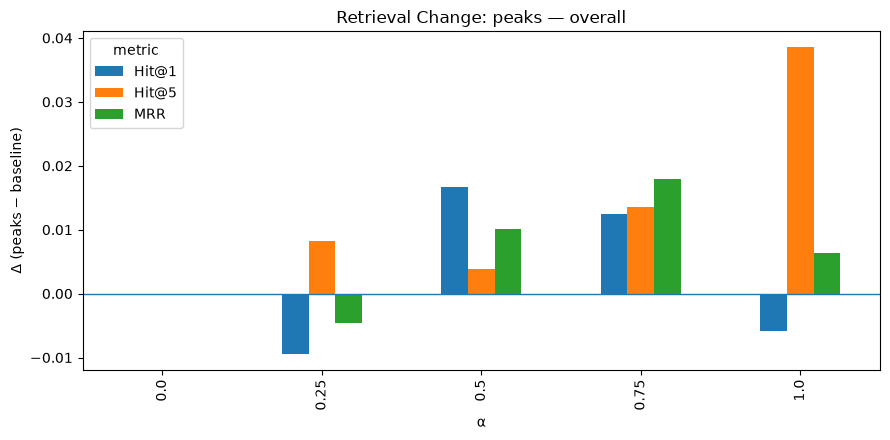

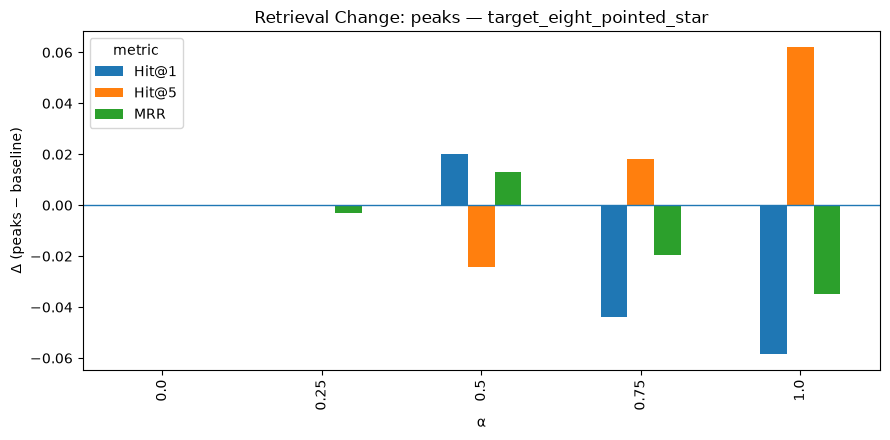

In [45]:
metric_names = {
    "hit_at_1": "Hit@1",
    "hit_at_5": "Hit@5",
    "mrr": "MRR",
}

for experiment in experiments:
    if experiment == "baseline":
        continue

    for scope in ("overall", "target_eight_pointed_star"):
        sub = (
            comparison[comparison["scope"] == scope]
            .pivot(
                index="alpha",
                columns="metric",
                values=f"delta_{experiment}"
            )
            .reindex(columns=metric_names.keys())
        )

        fig, ax = plt.subplots(figsize=(9, 4.5))

        sub.rename(columns=metric_names).plot(
            kind="bar",
            ax=ax
        )

        ax.axhline(0, linewidth=1)
        ax.set(
            title=f"Retrieval Change: {experiment} — {scope}",
            ylabel=f"Δ ({experiment} − baseline)",
            xlabel="α",
        )

        plt.tight_layout()
        plt.show()

## 3. Multi-class discrimination comparison

These are **pooled** precision, recall and F1 scores for Top-1 classification. Compare DINOv2 with Hybrid α=0.25, as stored in both JSON files.

In [46]:
def flatten_discrimination(data, experiment):
    rows = []

    for representation, report in data["multi_class_discrimination"].items():
        for label, scores in report["per_class"].items():
            rows.append({
                "experiment": experiment,
                "representation": representation,
                "class_or_average": label,
                "kind": "class",
                **scores,
            })

        for avg in ("micro_avg", "macro_avg", "weighted_avg"):
            rows.append({
                "experiment": experiment,
                "representation": representation,
                "class_or_average": avg,
                "kind": "average",
                **report[avg],
            })

    return pd.DataFrame(rows)


discrimination = pd.concat(
    [
        flatten_discrimination(data, name)
        for name, data in experiments.items()
    ],
    ignore_index=True,
)

keys = ["representation", "class_or_average", "kind"]
metrics = ["precision", "recall", "f1-score", "support"]

# Frozen baseline
baseline_discrimination = discrimination.loc[
    discrimination["experiment"] == "baseline",
    keys + metrics
]

# All other experiments
experiment_discrimination = discrimination.loc[
    discrimination["experiment"] != "baseline",
    ["experiment"] + keys + metrics
]

discrim_comparison = experiment_discrimination.merge(
    baseline_discrimination,
    on=keys,
    suffixes=("_experiment", "_baseline"),
    validate="many_to_one",
)

# Compute deltas
for metric in ("precision", "recall", "f1-score"):
    discrim_comparison[f"delta_{metric}"] = (
        discrim_comparison[f"{metric}_experiment"]
        - discrim_comparison[f"{metric}_baseline"]
    )

# Verify identical class supports
assert (
    discrim_comparison["support_baseline"]
    == discrim_comparison["support_experiment"]
).all(), "Different supports: check dataset and query exclusions."


def show_class_comparison(representation):
    cols = [
        "experiment",
        "class_or_average",
        "support_baseline",
        "precision_baseline",
        "precision_experiment",
        "delta_precision",
        "recall_baseline",
        "recall_experiment",
        "delta_recall",
        "f1-score_baseline",
        "f1-score_experiment",
        "delta_f1-score",
    ]

    sub = discrim_comparison.loc[
        (discrim_comparison["representation"] == representation)
        & (discrim_comparison["kind"] == "class"),
        cols,
    ]

    display(sub.round(4))


print("HYBRID α=0.25 — PER-CLASS TOP-1")
show_class_comparison("hybrid_025")

print("\nDINOv2 α=0.0 — PER-CLASS TOP-1")
show_class_comparison("dinov2")

HYBRID α=0.25 — PER-CLASS TOP-1


,experiment,class_or_average,support_baseline,precision_baseline,precision_experiment,delta_precision,recall_baseline,recall_experiment,delta_recall,f1-score_baseline,f1-score_experiment,delta_f1-score
9,peaks,eight_petal_rosette,34.0,0.6667,0.6111,-0.0556,0.6471,0.6471,0.0000,0.6567,0.6286,-0.0281
10,peaks,eight_pointed_star,52.0,0.5821,0.6000,0.0179,0.7500,0.7500,0.0000,0.6555,0.6667,0.0112
11,peaks,five_pointed_star,42.0,0.5854,0.5854,0.0000,0.5714,0.5714,0.0000,0.5783,0.5783,0.0000
12,peaks,rosette_other,31.0,0.6207,0.6538,0.0332,0.5806,0.5484,-0.0323,0.6000,0.5965,-0.0035
13,peaks,six_pointed_star,41.0,0.5714,0.5588,-0.0126,0.4878,0.4634,-0.0244,0.5263,0.5067,-0.0196
14,peaks,sunburst,37.0,0.8400,0.8750,0.0350,0.5676,0.5676,0.0000,0.6774,0.6885,0.0111



DINOv2 α=0.0 — PER-CLASS TOP-1


,experiment,class_or_average,support_baseline,precision_baseline,precision_experiment,delta_precision,recall_baseline,recall_experiment,delta_recall,f1-score_baseline,f1-score_experiment,delta_f1-score
0,peaks,eight_petal_rosette,34.0,0.5556,0.5556,0.0,0.5882,0.5882,0.0,0.5714,0.5714,0.0
1,peaks,eight_pointed_star,52.0,0.6724,0.6724,0.0,0.7500,0.7500,0.0,0.7091,0.7091,0.0
2,peaks,five_pointed_star,42.0,0.5957,0.5957,0.0,0.6667,0.6667,0.0,0.6292,0.6292,0.0
3,peaks,rosette_other,31.0,0.5000,0.5000,0.0,0.5484,0.5484,0.0,0.5231,0.5231,0.0
4,peaks,six_pointed_star,41.0,0.6129,0.6129,0.0,0.4634,0.4634,0.0,0.5278,0.5278,0.0
5,peaks,sunburst,37.0,0.8750,0.8750,0.0,0.5676,0.5676,0.0,0.6885,0.6885,0.0


### 3.1 Compare micro/macro/weighted averages

In [47]:
avg_cols = [
    "experiment", "representation", "class_or_average",
    "support_baseline",
    "precision_baseline", "precision_experiment", "delta_precision",
    "recall_baseline", "recall_experiment", "delta_recall",
    "f1-score_baseline", "f1-score_experiment", "delta_f1-score",
]

display(
    discrim_comparison.loc[
        discrim_comparison["kind"] == "average",
        avg_cols
    ]
    .sort_values(["experiment", "representation", "class_or_average"])
    .round(4)
)

,experiment,representation,class_or_average,support_baseline,precision_baseline,precision_experiment,delta_precision,recall_baseline,recall_experiment,delta_recall,f1-score_baseline,f1-score_experiment,delta_f1-score
7,peaks,dinov2,macro_avg,237.0,0.6353,0.6353,0.0000,0.5974,0.5974,0.0000,0.6082,0.6082,0.0000
6,peaks,dinov2,micro_avg,237.0,0.6261,0.6261,0.0000,0.6076,0.6076,0.0000,0.6167,0.6167,0.0000
8,peaks,dinov2,weighted_avg,237.0,0.6408,0.6408,0.0000,0.6076,0.6076,0.0000,0.6163,0.6163,0.0000
16,peaks,hybrid_025,macro_avg,237.0,0.6444,0.6474,0.0030,0.6008,0.5913,-0.0094,0.6157,0.6109,-0.0048
15,peaks,hybrid_025,micro_avg,237.0,0.6261,0.6283,0.0022,0.6076,0.5992,-0.0084,0.6167,0.6134,-0.0033
17,peaks,hybrid_025,weighted_avg,237.0,0.6383,0.6419,0.0036,0.6076,0.5992,-0.0084,0.6158,0.6121,-0.0037


### 3.2 Per-class precision, recall, and F1 deltas

This helps answer whether harmonics improve discrimination of five-, six-, and eight-pointed stars (the **point-counting problem**).

- **Precision:** Do harmonics reduce false positives for individual star classes?
- **Recall:** Do harmonics improve identification of actual five-, six-, and eight-pointed stars?
- **F1-score:** Do harmonics improve the balance between precision and recall?

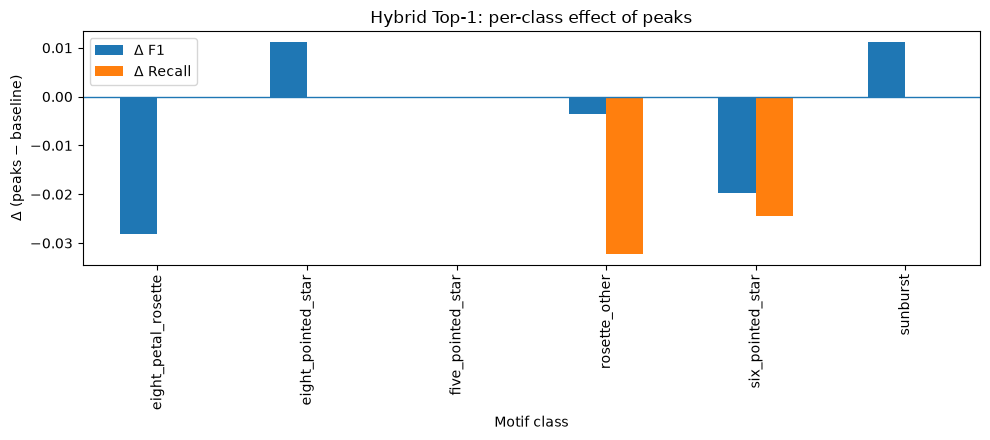


Star classes only — peaks


,precision_baseline,precision_experiment,delta_precision,recall_baseline,recall_experiment,delta_recall,f1-score_baseline,f1-score_experiment,delta_f1-score
class_or_average,,,,,,,,,
five_pointed_star,0.5854,0.5854,0.0000,0.5714,0.5714,0.0000,0.5783,0.5783,0.0000
six_pointed_star,0.5714,0.5588,-0.0126,0.4878,0.4634,-0.0244,0.5263,0.5067,-0.0196
eight_pointed_star,0.5821,0.6000,0.0179,0.7500,0.7500,0.0000,0.6555,0.6667,0.0112


In [48]:
star_labels = [
    "five_pointed_star",
    "six_pointed_star",
    "eight_pointed_star",
]

metrics = [
    "precision_baseline", "precision_experiment", "delta_precision",
    "recall_baseline", "recall_experiment", "delta_recall",
    "f1-score_baseline", "f1-score_experiment", "delta_f1-score",
]

for experiment in experiments:
    if experiment == "baseline":
        continue

    sub = discrim_comparison.loc[
        (discrim_comparison["experiment"] == experiment) &
        (discrim_comparison["representation"] == "hybrid_025") &
        (discrim_comparison["kind"] == "class")
    ].copy()

    sub = sub.set_index("class_or_average")

    # Per-class F1 and Recall deltas
    fig, ax = plt.subplots(figsize=(10, 4.5))

    sub[["delta_f1-score", "delta_recall"]].rename(
        columns={
            "delta_f1-score": "Δ F1",
            "delta_recall": "Δ Recall",
        }
    ).plot(kind="bar", ax=ax)

    ax.axhline(0, linewidth=1)
    ax.set(
        title=f"Hybrid Top-1: per-class effect of {experiment}",
        ylabel=f"Δ ({experiment} − baseline)",
        xlabel="Motif class",
    )

    plt.tight_layout()
    plt.show()

    # Star-class discrimination
    print(f"\nStar classes only — {experiment}")

    display(
        sub.loc[star_labels, metrics].round(4)
    )

## 4. Confusion Pattern Analysis

Investigate whether geometric feature improvements reduce
systematic misclassification between visually similar motifs.

Focus:
- Five-, six-, and eight-pointed star confusion.
- Changes in misclassification patterns relative to baseline.
- Whether improvements in recall introduce new false positives.

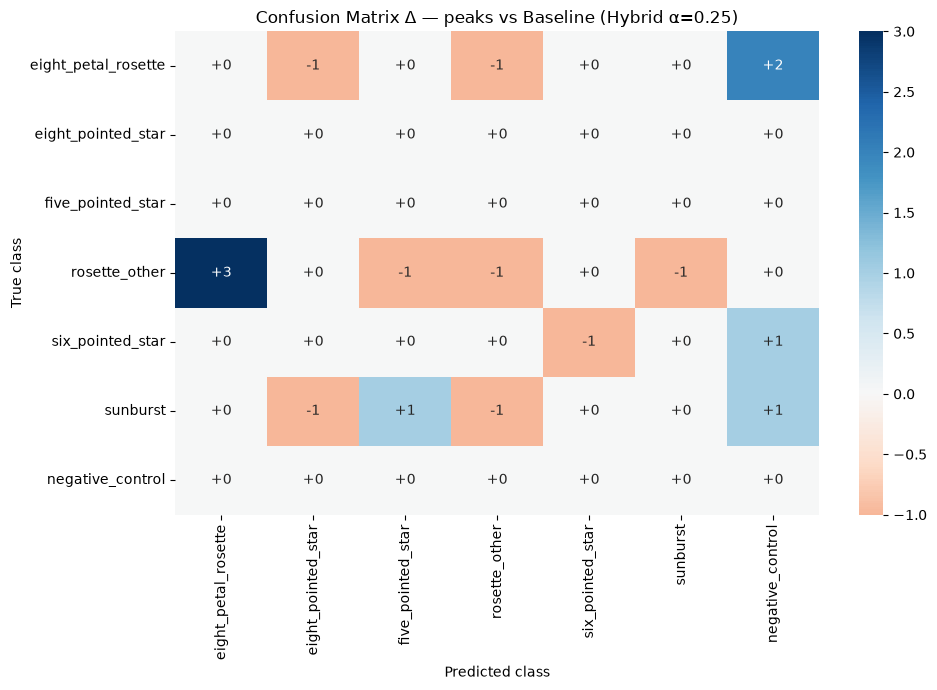

In [49]:
representation = "hybrid_025"

baseline_cm = experiments["baseline"]["multi_class_discrimination"][representation]
labels = baseline_cm["confusion_matrix_labels"]
cm_baseline = np.asarray(baseline_cm["confusion_matrix"])

for experiment, data in experiments.items():
    if experiment == "baseline":
        continue

    current_cm = data["multi_class_discrimination"][representation]

    assert labels == current_cm["confusion_matrix_labels"], (
        f"Class label mismatch: {experiment}"
    )

    cm_current = np.asarray(current_cm["confusion_matrix"])
    delta_cm = cm_current - cm_baseline

    fig, ax = plt.subplots(figsize=(10, 7))

    sns.heatmap(
        delta_cm,
        annot=True,
        fmt="+d",
        cmap="RdBu",
        center=0,
        xticklabels=labels,
        yticklabels=labels,
        ax=ax,
    )

    ax.set(
        title=f"Confusion Matrix Δ — {experiment} vs Baseline (Hybrid α=0.25)",
        xlabel="Predicted class",
        ylabel="True class",
    )

    fig.tight_layout()

    # Save into the corresponding experiment directory
    output = experiment_paths[experiment].parent / "figures"
    output.mkdir(parents=True, exist_ok=True)

    fig.savefig(
        output / "confusion_delta_hybrid.png",
        dpi=300,
        bbox_inches="tight",
    )

    # Optional vector format
    fig.savefig(
        output / "confusion_delta_hybrid.svg",
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

## 5. Notes for Interpreting Feature-Ablation Experiments

- A modest mean improvement should be checked against **fold variability**; five folds do not establish statistical significance by themselves.
- **Pooled macro F1** may differ from mean fold-level macro F1 because they use different averaging procedures.
- **DINOv2 (α=0.0)** serves as a control: adding geometric features should not change embedding-only results when all other conditions remain fixed.
- A higher **Hit@5** does not necessarily imply better Top-1 classification; voting performance is evaluated separately using `class_voting.json`.
- All experiments must use identical dataset partitions, CV folds, and evaluation protocols to ensure comparability.
- The **held-out test set** must remain untouched during feature selection and should only be used for final evaluation of the selected configuration.